# Описание данных

Данные - специально подготовленная выборка из полного набора, описанного здесь: https://mengtingwan.github.io/data/goodreads#datasets с дополнениями из https://www.kaggle.com/datasets/austinreese/goodreads-books:
- books: перечень книг (~44 тыс.) из списка https://www.goodreads.com/list/show/1.Best_Books_Ever (совпадение по book id),
- interactions: взаимодействие пользователей с книгами

Основной массив данных был собран в конце 2017.

# Инициализация

In [80]:
%pip install pandas

You should consider upgrading via the '/Users/rustammutalipov/mle-recsys-start/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [81]:
%pip install matplotlib

You should consider upgrading via the '/Users/rustammutalipov/mle-recsys-start/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [82]:
%pip install fastparquet

You should consider upgrading via the '/Users/rustammutalipov/mle-recsys-start/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [83]:
import logging
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [84]:
%matplotlib inline
%config InlineBackend.figure_format = 'png'
%config InlineBackend.figure_format = 'retina'

Создаём логгер, который удобен для использования в ноутбуке.

# Load Data

Загружаем данные как они есть, начинаем на них смотреть: какие в них есть сущности, атрибуты, распределения.

In [85]:
import sys
import pandas as pd
import pyarrow as pa

print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("PyArrow:", pa.__version__)

Python: 3.9.6 (default, May  7 2023, 23:32:44) 
[Clang 14.0.3 (clang-1403.0.22.14.1)]
Pandas: 2.1.1
PyArrow: 13.0.0


In [86]:
books = pd.read_parquet(
    "/Users/rustammutalipov/mle-recsys-start/books.parquet",
    engine="fastparquet"
)



In [87]:
books.info()

<class 'pandas.core.frame.DataFrame'>
Index: 43312 entries, 3.0 to 2360448.0
Columns: 833 entries, book_id to genre_and_votes_dict.th Century
dtypes: Int64(3), bool(1), float64(816), int64(2), object(11)
memory usage: 275.4+ MB


Пример данных по книгам

In [88]:
print(books[["book_id", "author", "title", "num_pages", "average_rating"]].sample(5, random_state=52).sort_values("book_id").set_index("book_id").to_string())

                                             author                                            title  num_pages  average_rating
book_id                                                                                                                        
69882                 Heinrich Böll, Patrick Bowles                      Billiards at Half-Past Nine        288            3.93
267533                               Robert Cormier                                         8 Plus 1        173            3.67
820966    Martin Luther, J.I. Packer, O.R. Johnston                          The Bondage of the Will        322            4.17
4532622                               Karen Hancock                                      The Enclave        492            3.82
20444381                             Diana Gabaldon  Os tambores de outono - 1ª Parte (Outlander #4)       1048            3.99


In [89]:
interactions = pd.read_parquet("/Users/rustammutalipov/mle-recsys-start/interactions.parquet", engine="fastparquet")


Можно оценить объём данных о взаимодействиях

In [90]:
interactions.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12890434 entries, 0 to 12914458
Data columns (total 7 columns):
 #   Column       Dtype 
---  ------       ----- 
 0   user_id      object
 1   book_id      int64 
 2   started_at   object
 3   read_at      object
 4   is_read      bool  
 5   rating       int64 
 6   is_reviewed  bool  
dtypes: bool(2), int64(2), object(3)
memory usage: 614.7+ MB


Пример данных по взаимодействиям

In [91]:
print(interactions[["user_id", "book_id", "started_at", "read_at", "is_read", "rating"]].sample(5, random_state=52).sort_values("user_id").set_index(["user_id", "book_id"]).to_string())

                                                    started_at              read_at  is_read  rating
user_id                          book_id                                                            
0447747f44c0d8d1a08cf329fe253f29 10054335  1460073600000000000  1461110400000000000     True       3
14432756ffba6357686f09e4ccc332bb 26252859  1464307200000000000  1464566400000000000     True       5
46d6c8cf548d1c86abb671f42ba71b5e 960       1407283200000000000  1477699200000000000     True       5
71c2b3714945af1f700f49953904c510 18492859  1412812800000000000  1413072000000000000     True       5
7802bafdeac8abff23a72b9dd60b1dd1 18710190  1425168000000000000  1430784000000000000     True       4


# EDA

Посмотрим на данные о книгах, какие поля есть.

In [92]:
books.sample(3).T

,61405.0,187278.0,518190.0
book_id,88868,15704459,1091800
author,Gore Vidal,Brandon Sanderson,Alexander Kent
title,United States: Essays 1952-1992,"Firefight (The Reckoners, #2)","To Glory We Steer (Richard Bolitho, #7)"
description,From the age of Eisenhower to the dawning of t...,"Babylon Restored, formerly Manhattan, may give...","Portsmouth, 1782. His Britannic Majesty's frig..."
genre_and_votes,"{'Writing-Essays': 74, 'History': 46, 'Nonfict...","{'Fantasy': 2300, 'Young Adult': 1101, 'Scienc...","{'Historical-Historical Fiction': 39, 'Fiction..."
...,...,...,...
genre_and_votes_dict.k,NaN,NaN,NaN
genre_and_votes_dict.nd Grade,NaN,NaN,NaN
genre_and_votes_dict.st Century,NaN,NaN,NaN
genre_and_votes_dict.st Grade,NaN,NaN,NaN


Посмотрим на данные о взаимодействиях пользователей с книгами.

In [93]:
books["book_id"].nunique()

43312

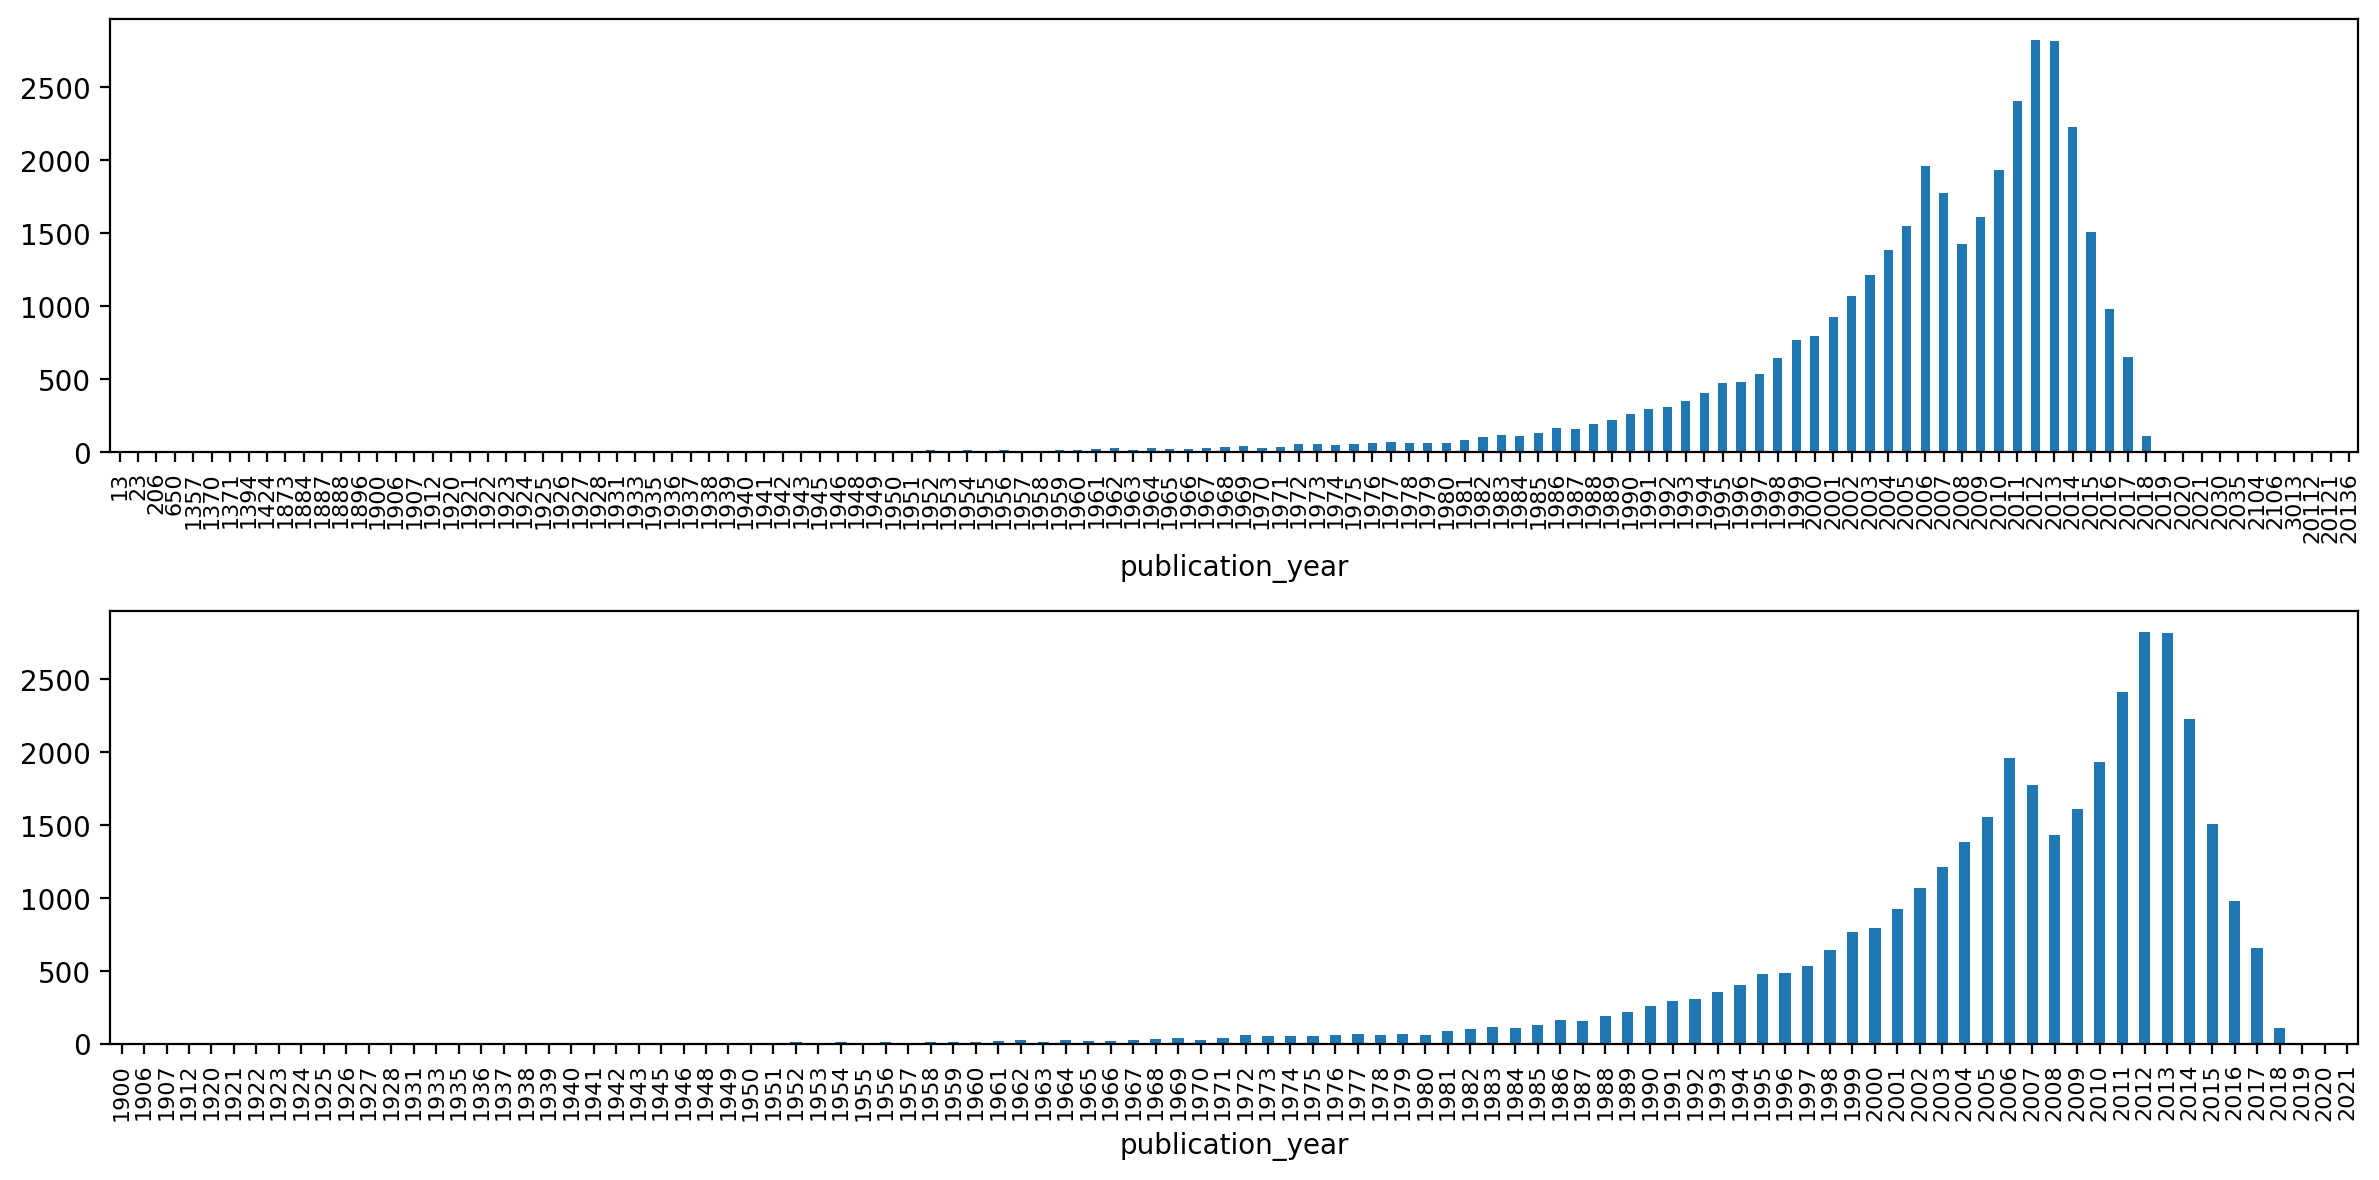

In [94]:
# распределение книг по годам публикации

fig, axs = plt.subplots(2, 1, figsize=(12, 6))

ax = axs[0]
books["publication_year"].value_counts().sort_index().plot(kind="bar", ax=ax)
ax.tick_params(axis='x', labelsize=8)

ax = axs[1]
books.query("publication_year >= 1900 and publication_year <= 2025")["publication_year"].value_counts().sort_index().plot(kind="bar", ax=ax)
ax.tick_params(axis='x', labelsize=8)

fig.tight_layout()

# События по месяцам

In [95]:
from pandas.tseries.offsets import MonthEnd

interactions["started_at_month"] = pd.to_datetime(interactions["started_at"]).dt.to_period('M').dt.to_timestamp().dt.date

In [96]:
interactions_by_month = interactions.groupby("started_at_month").agg(events=("started_at", "count"), users=("user_id", "nunique")).reset_index()

In [97]:
interactions_by_month

,started_at_month,events,users
0,2007-01-01,1993,1071
1,2007-02-01,201,135
2,2007-03-01,222,152
3,2007-04-01,201,135
4,2007-05-01,204,138
...,...,...,...
127,2017-08-01,202129,93040
128,2017-09-01,172187,82694
129,2017-10-01,108107,58076
130,2017-11-01,565,475


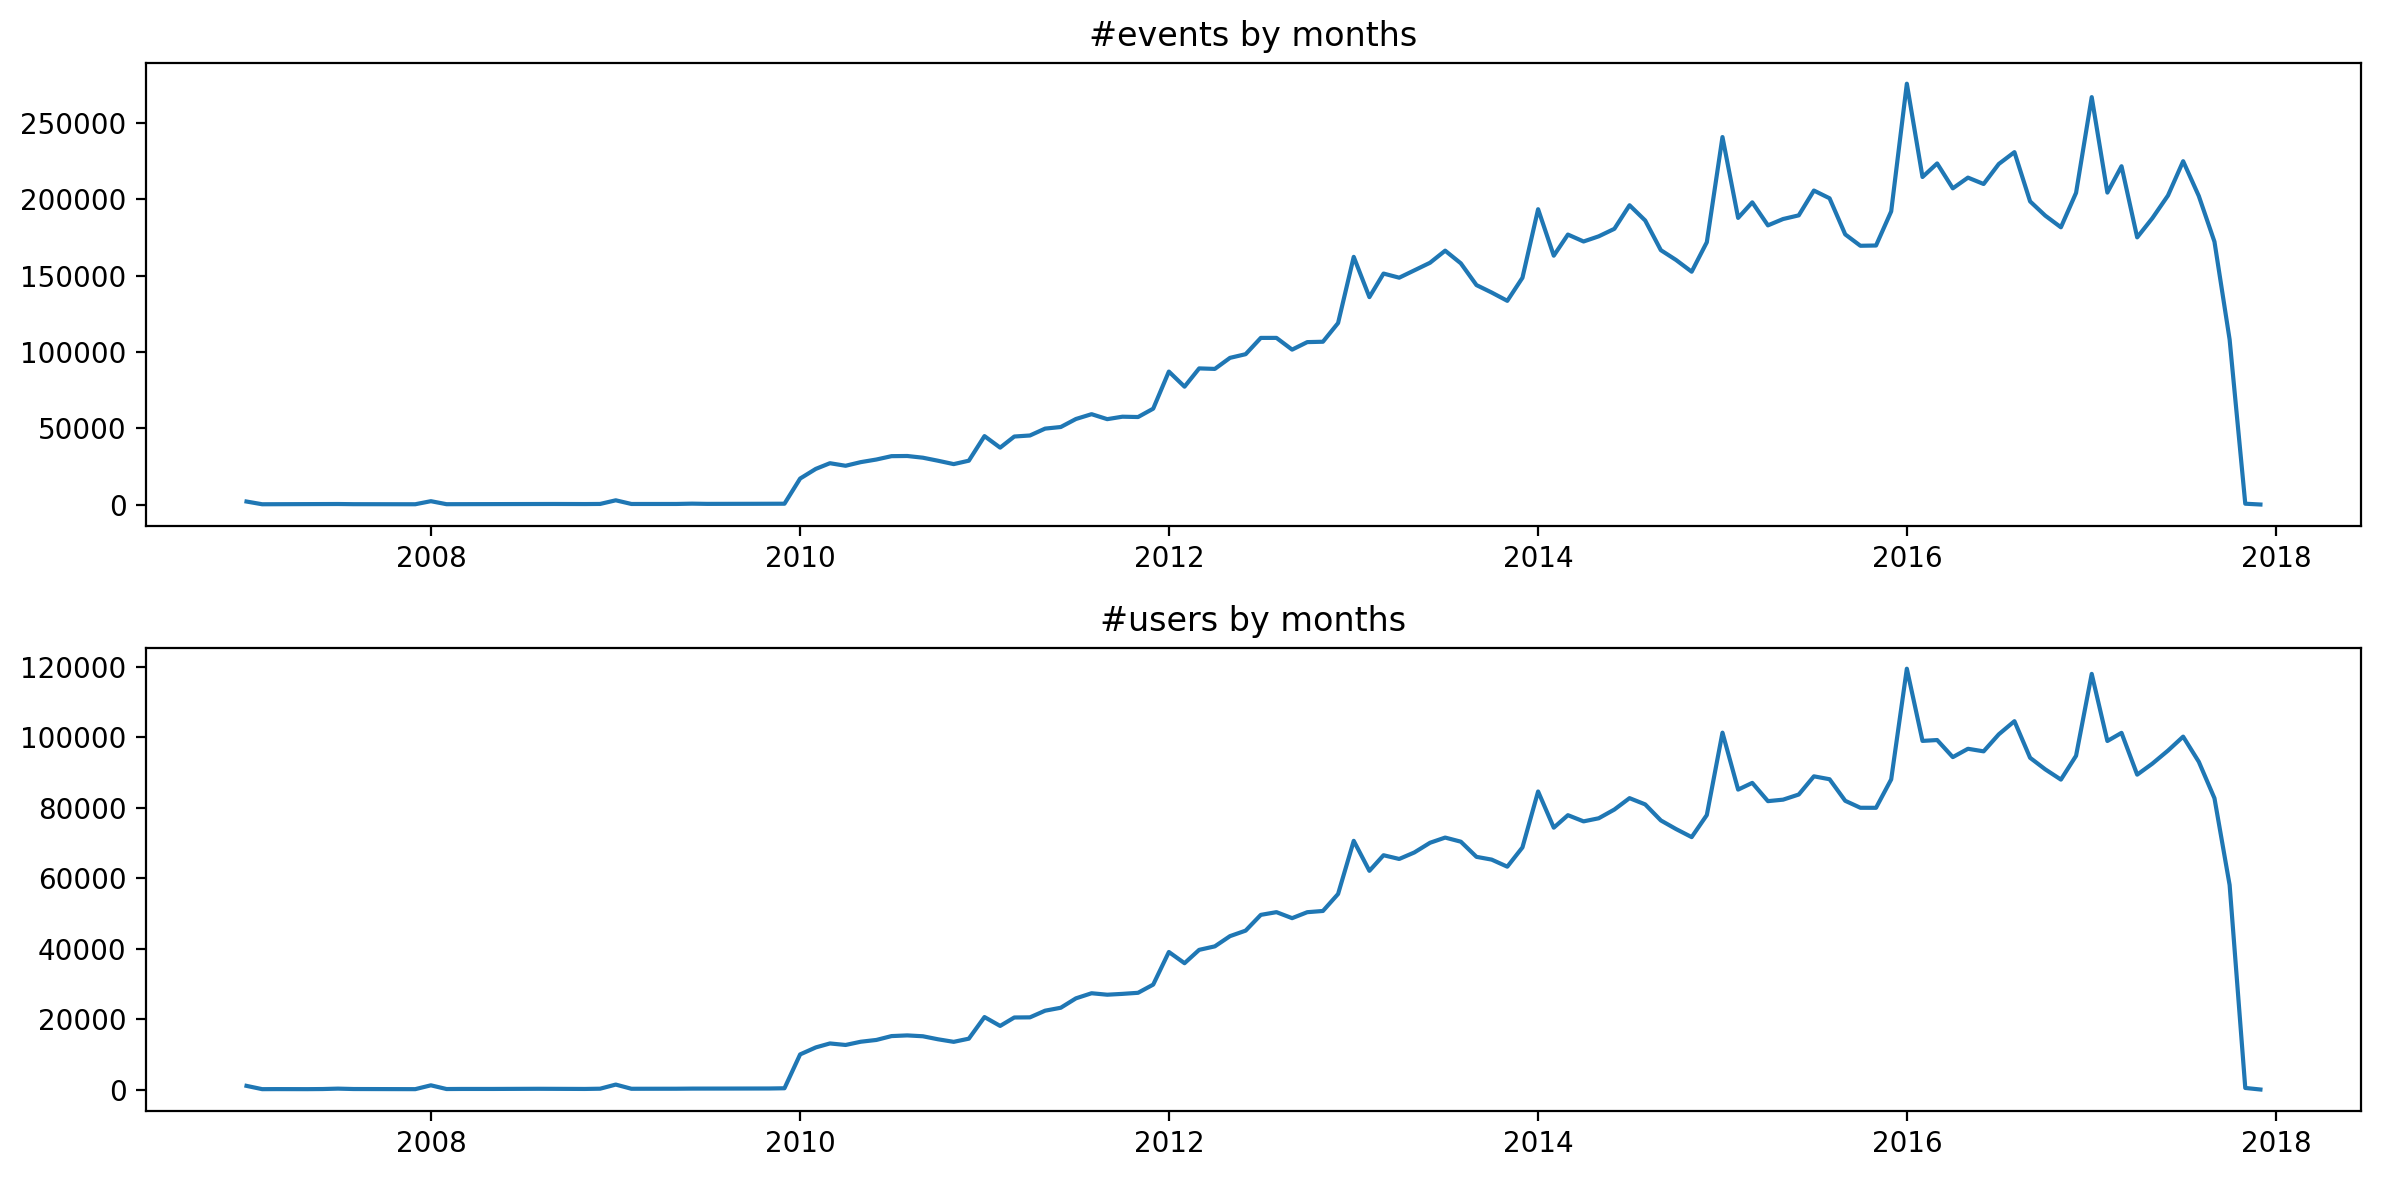

In [98]:
# распределение взаимодействий по годам

fig, axs = plt.subplots(2, 1, figsize=(12, 6))

ax = axs[0]
ax.plot(interactions_by_month["started_at_month"], interactions_by_month["events"])
# ax.tick_params(axis='x', labelsize=8)
ax.set_title("#events by months")

ax = axs[1]
ax.plot(interactions_by_month["started_at_month"], interactions_by_month["users"])
# ax.tick_params(axis='x', labelsize=8)
ax.set_title("#users by months")

fig.tight_layout()

# Преобработка

Примем новые именования:
- books -> items (более обобщённое название)
- interactions -> events (несколько короче, удобнее в коде)

In [99]:
items = books.copy()
events = interactions.copy()

In [100]:
del books
del interactions

In [101]:
# оставим события только до ноября 2017

# Преобразуем даты
events["started_at"] = pd.to_datetime(
    events["started_at"], errors="coerce"
)

events["read_at"] = pd.to_datetime(
    events["read_at"], errors="coerce"
)

# Дата отсечения
event_cutoff_date = pd.Timestamp("2017-11-01")

# Исключаем события после 31 октября 2017 года
events = events.loc[
    (events["started_at"].isna() |
     (events["started_at"] < event_cutoff_date))
    &
    (events["read_at"].isna() |
     (events["read_at"] < event_cutoff_date))
].copy()

In [102]:
events = events.loc[
    events["rating"].notna() &
    (events["rating"] > 0)
].copy()

In [103]:
events = events.loc[
    events["is_read"] == True
].copy()

In [104]:
# Считаем количество уникальных книг каждого пользователя
user_books_count = events.groupby("user_id")["book_id"].nunique()

# Выбираем пользователей с двумя и более книгами
valid_users = user_books_count[
    user_books_count >= 2
].index

# Фильтруем события
events = events.loc[
    events["user_id"].isin(valid_users)
].copy()

In [105]:
items = items.rename(columns={"book_id": "item_id"})
events = events.rename(columns={"book_id": "item_id"})

In [106]:
# Получаем отсортированные уникальные ID
user_ids = sorted(events["user_id"].unique())

# Создаём словарь соответствий
user_id_map = {
    old_id: new_id
    for new_id, old_id in enumerate(user_ids, start=1000000)
}

# Заменяем идентификаторы
events["user_id"] = events["user_id"].map(user_id_map)

In [107]:
print("Количество событий:", len(events))
print("Количество пользователей:", events["user_id"].nunique())
print("Количество книг:", events["item_id"].nunique())

print("\nМинимальный user_id:", events["user_id"].min())
print("Максимальный user_id:", events["user_id"].max())

print("\nРаспределение рейтингов:")
print(events["rating"].value_counts().sort_index())

print("\nКоличество прочитанных книг на пользователя:")
print(
    events.groupby("user_id")["item_id"]
    .nunique()
    .describe()
)

display(events.head())

Количество событий: 11751086
Количество пользователей: 430585
Количество книг: 41673

Минимальный user_id: 1000000
Максимальный user_id: 1430584

Распределение рейтингов:
rating
1     182356
2     667366
3    2549892
4    4528257
5    3823215
Name: count, dtype: int64

Количество прочитанных книг на пользователя:
count    430585.000000
mean         27.290979
std          45.886977
min           2.000000
25%           4.000000
50%          11.000000
75%          30.000000
max        3140.000000
Name: item_id, dtype: float64


,user_id,item_id,started_at,read_at,is_read,rating,is_reviewed,started_at_month
0,1229132,22034,2015-07-12,2015-07-17,True,5,False,2015-07-01
1,1229132,22318578,2015-06-07,2015-08-09,True,5,True,2015-06-01
2,1229132,22551730,2015-06-24,2015-07-11,True,4,True,2015-06-01
3,1229132,22816087,2015-09-27,2015-11-04,True,5,True,2015-09-01
5,1229132,17910054,2015-03-04,2015-07-28,True,3,False,2015-03-01


In [108]:
assert (events["rating"] > 0).all()
assert events["is_read"].all()

assert (
    events.groupby("user_id")["item_id"].nunique() >= 2
).all()

assert events["user_id"].min() == 1000000

assert (
    events["user_id"].nunique()
    == events["user_id"].max() - 1000000 + 1
)

assert (
    events["started_at"].dropna() < event_cutoff_date
).all()

assert (
    events["read_at"].dropna() < event_cutoff_date
).all()

print("Все проверки пройдены!")

Все проверки пройдены!


# Ваш код здесь

In [110]:
users_count = events["user_id"].nunique()
books_count = events["item_id"].nunique()

print(f"Количество пользователей: {users_count:,}")
print(f"Количество книг: {books_count:,}")
print(f"Количество взаимодействий: {len(events):,}")

Количество пользователей: 430,585
Количество книг: 41,673
Количество взаимодействий: 11,751,086


Среднее количество: 27.29
Медиана: 11.00


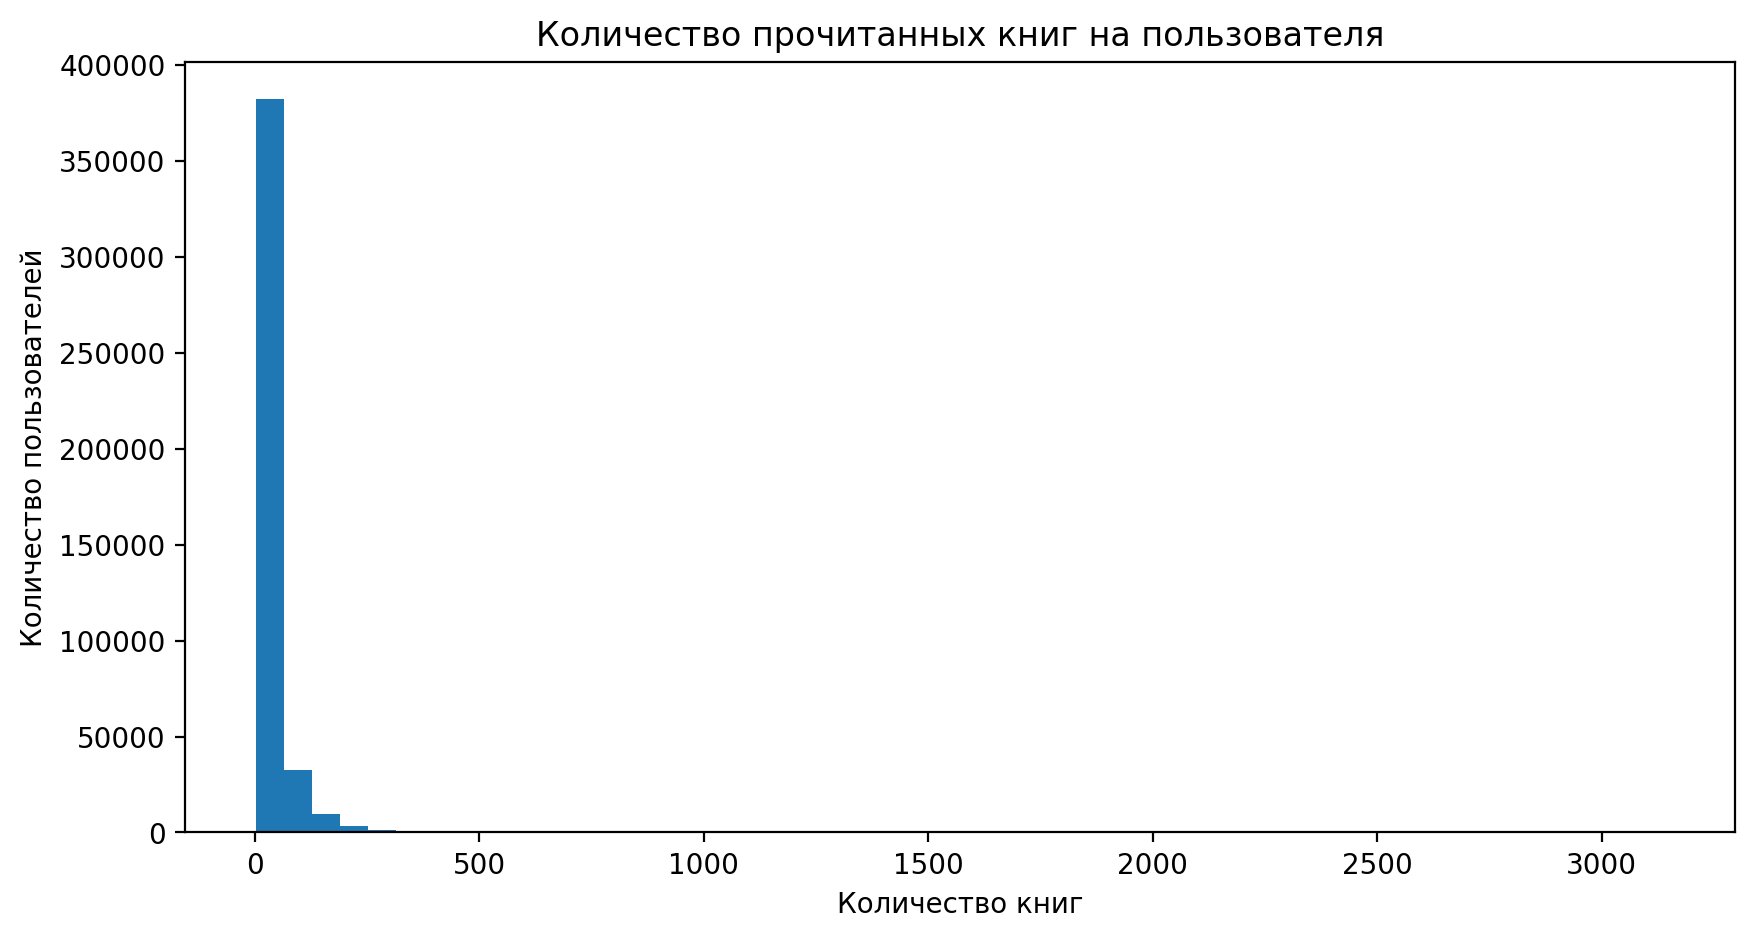

In [112]:
# Выбираем только прочитанные книги
read_events = events[events["is_read"] == True].copy()

# Считаем уникальные книги каждого пользователя
books_per_user = (
    read_events.groupby("user_id")["item_id"]
    .nunique()
    .reindex(events["user_id"].unique(), fill_value=0)
)

print(f"Среднее количество: {books_per_user.mean():.2f}")
print(f"Медиана: {books_per_user.median():.2f}")

plt.figure(figsize=(10, 5))
plt.hist(books_per_user, bins=50)
plt.title("Количество прочитанных книг на пользователя")
plt.xlabel("Количество книг")
plt.ylabel("Количество пользователей")
plt.show()

In [114]:
missing_rating = (
    (read_events["rating"].isna() | (read_events["rating"] == 0))
    .mean() * 100
)

print(f"Доля без рейтинга: {missing_rating:.2f}%")

Доля без рейтинга: 0.00%


rating
1     182356
2     667366
3    2549892
4    4528257
5    3823215
Name: count, dtype: int64


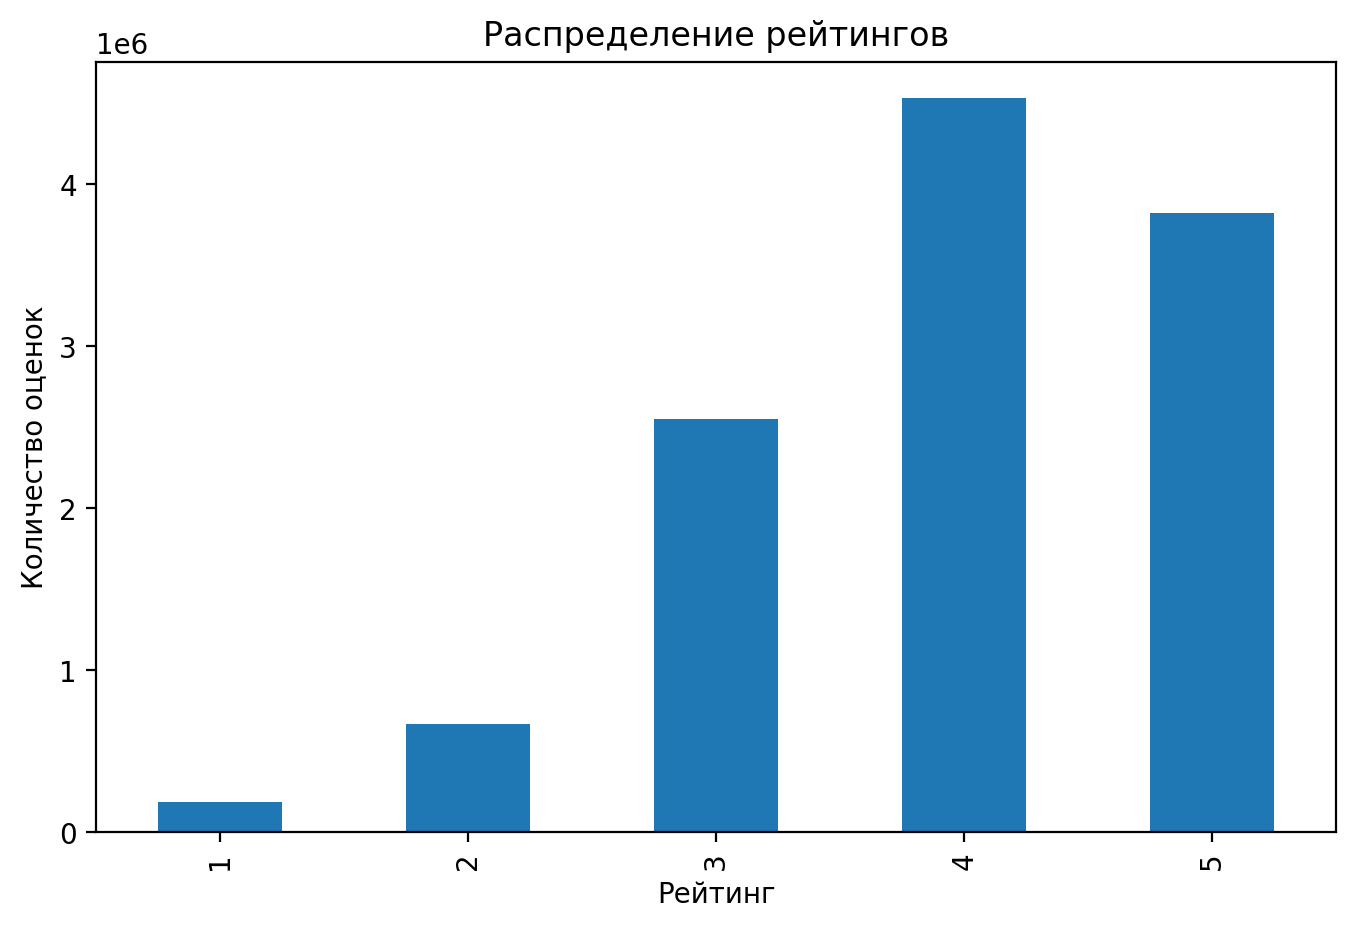

In [115]:
rating_counts = events["rating"].value_counts().sort_index()

print(rating_counts)

plt.figure(figsize=(8, 5))
rating_counts.plot(kind="bar")

plt.title("Распределение рейтингов")
plt.xlabel("Рейтинг")
plt.ylabel("Количество оценок")
plt.show()

count    41673.000000
mean         0.000655
std          0.002481
min          0.000002
25%          0.000026
50%          0.000109
75%          0.000416
max          0.096139
Name: user_id, dtype: float64


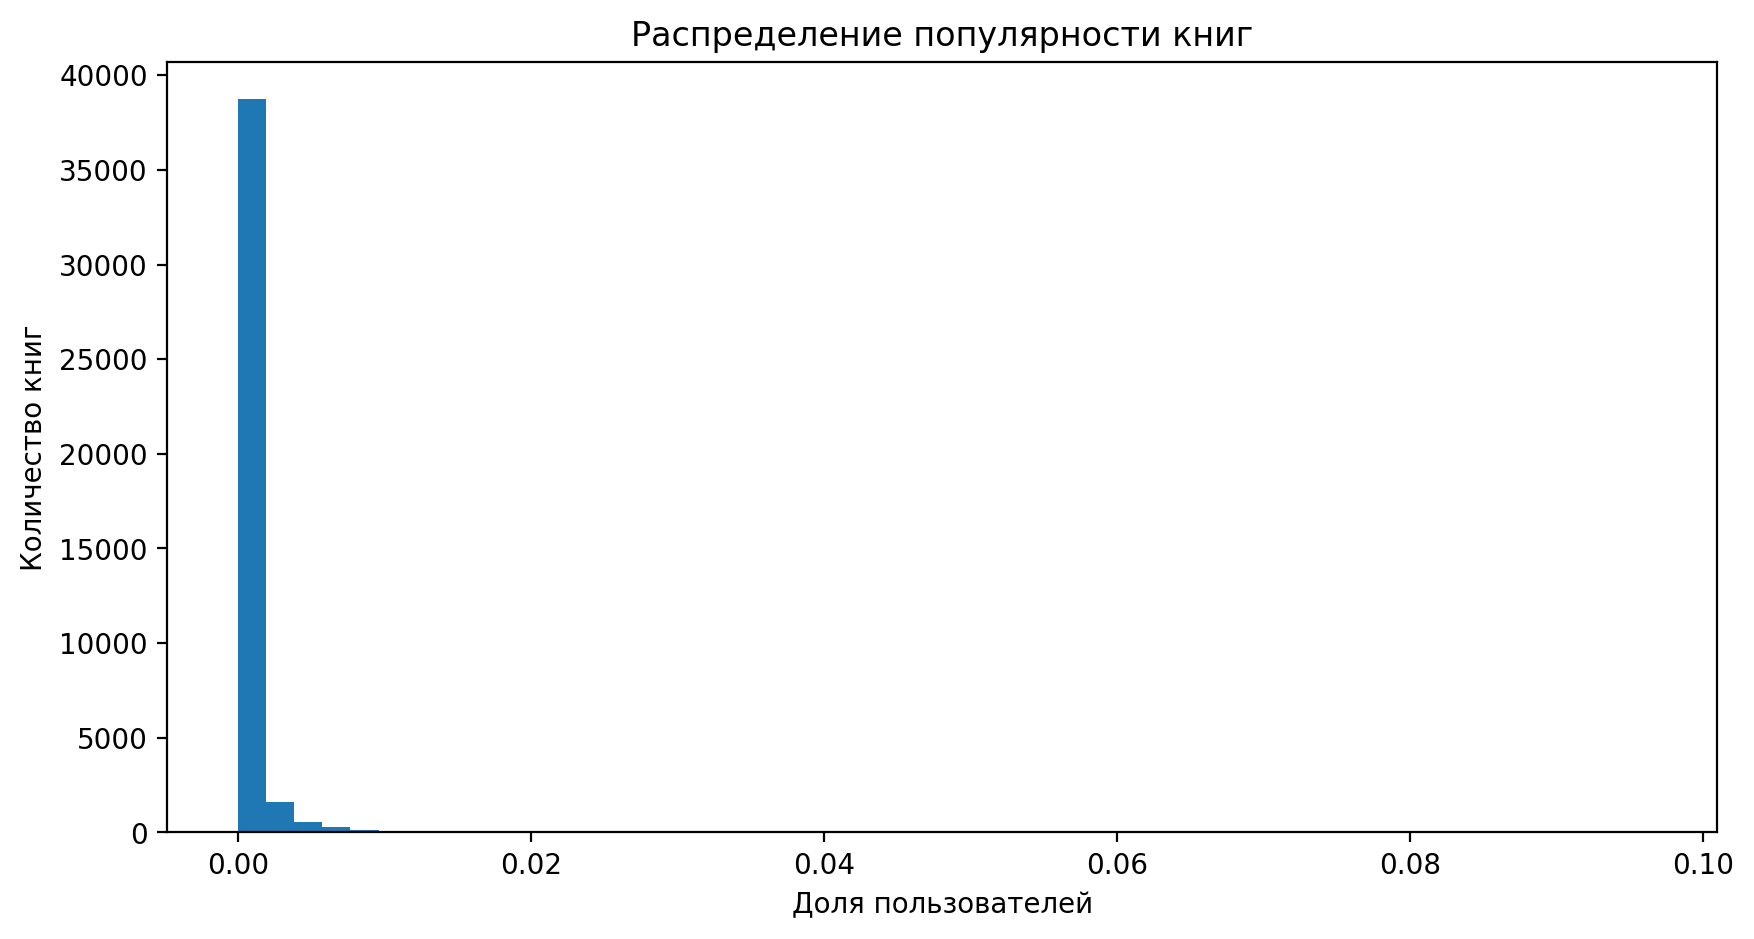

In [117]:
book_popularity = (
    events.groupby("item_id")["user_id"].nunique()
    / users_count
)

print(book_popularity.describe())

plt.figure(figsize=(10, 5))
plt.hist(book_popularity, bins=50)

plt.title("Распределение популярности книг")
plt.xlabel("Доля пользователей")
plt.ylabel("Количество книг")
plt.show()

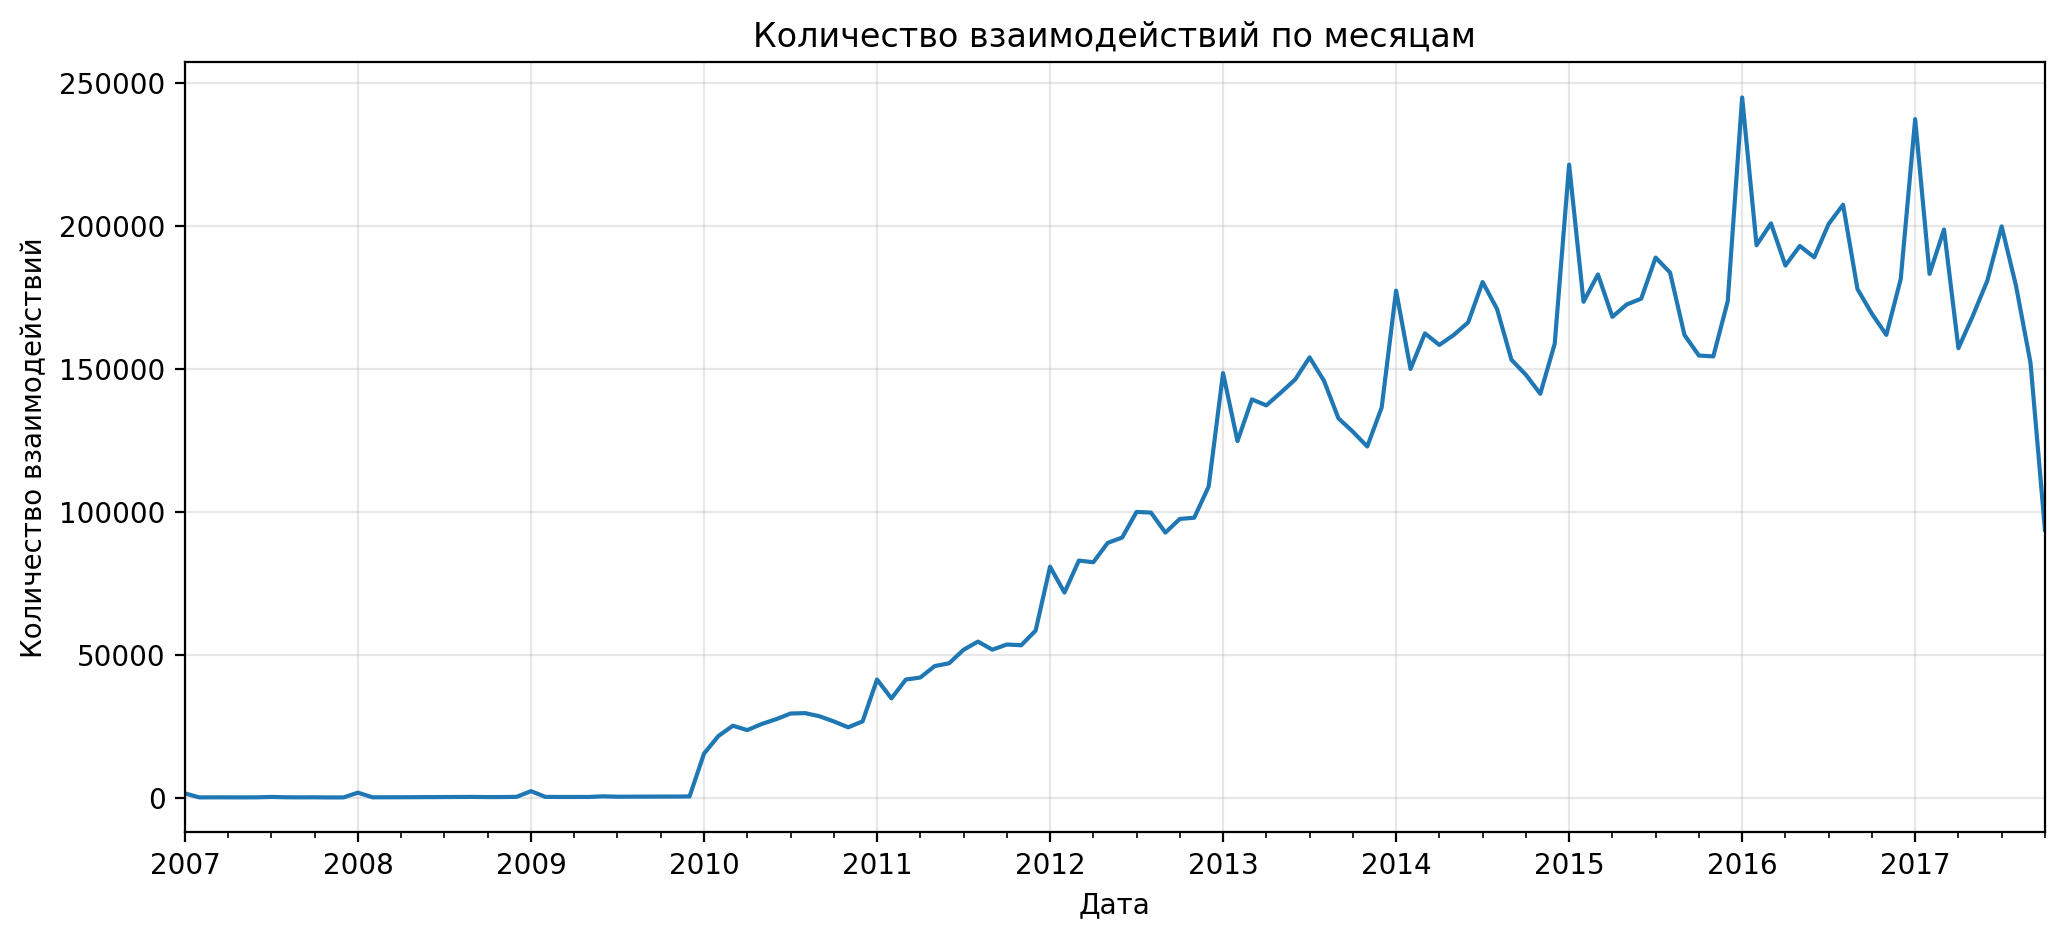

In [118]:
events_by_month = (
    events.groupby(
        events["started_at"].dt.to_period("M")
    )
    .size()
)

events_by_month.index = events_by_month.index.to_timestamp()

plt.figure(figsize=(12, 5))
events_by_month.plot()

plt.title("Количество взаимодействий по месяцам")
plt.xlabel("Дата")
plt.ylabel("Количество взаимодействий")
plt.grid(alpha=0.3)
plt.show()

In [120]:
# Пропущенные значения
print("Пропуски:")
print(events.isna().sum())

# Дубликаты
print("\nДубликаты:", events.duplicated().sum())

# Повторные взаимодействия с одной книгой
duplicates = events.duplicated(
    subset=["user_id", "item_id"]
).sum()

print("Повторные пары пользователь-книга:", duplicates)

# Некорректные даты
invalid_dates = (
    events["read_at"] < events["started_at"]
).sum()

print("Некорректные даты:", invalid_dates)

# Распределение рейтингов
print("\nЗначения рейтингов:")
print(events["rating"].value_counts(dropna=False).sort_index())

# Проверка книг, отсутствующих в каталоге
missing_books = (
    ~events["item_id"].isin(items["item_id"])
).sum()

print("Взаимодействия с неизвестными книгами:", missing_books)

Пропуски:
user_id             0
item_id             0
started_at          0
read_at             0
is_read             0
rating              0
is_reviewed         0
started_at_month    0
dtype: int64

Дубликаты: 0
Повторные пары пользователь-книга: 0
Некорректные даты: 0

Значения рейтингов:
rating
1     182356
2     667366
3    2549892
4    4528257
5    3823215
Name: count, dtype: int64
Взаимодействия с неизвестными книгами: 0


# Сохранение результатов

In [121]:
# Сохранение результатов
items.to_parquet("items.parquet", index=False)
events.to_parquet("events.parquet", index=False)

print("Данные успешно сохранены!")

Данные успешно сохранены!


In [125]:
# зададим точку разбиения
train_test_global_time_split_date = pd.to_datetime("2017-08-01")

train_test_global_time_split_idx = (
    events["started_at"] < train_test_global_time_split_date
)

events_train = events[train_test_global_time_split_idx]
events_test = events[~train_test_global_time_split_idx]

# количество пользователей в train и test
users_train = events_train["user_id"].drop_duplicates()
users_test = events_test["user_id"].drop_duplicates()

# количество пользователей, которые есть и в train, и в test
common_users = users_train[users_train.isin(users_test)]

print(len(users_train), len(users_test), len(common_users))

428220 123223 120858


In [127]:
cold_users = users_test[~users_test.isin(users_train)]

print(len(cold_users))

2365


In [128]:
from sklearn.preprocessing import MinMaxScaler

top_pop_start_date = pd.to_datetime("2015-01-01").date()

item_popularity = events_train \
    .query("started_at >= @top_pop_start_date") \
    .groupby(["item_id"]).agg(users=("user_id", "nunique"), avg_rating=("rating", "mean")).reset_index()

# нормализация пользователей и среднего рейтинга, требуется для их приведения к одному масштабу
scaler = MinMaxScaler()
item_popularity[["users_norm", "avg_rating_norm"]] = scaler.fit_transform(
    item_popularity[["users", "avg_rating"]]
)

# вычисляем popularity_score, как скор популярности со штрафом за низкий рейтинг
item_popularity["popularity_score"] = (
    item_popularity["users_norm"] * item_popularity["avg_rating_norm"]
)

# Сортируем по убыванию popularity_score
item_popularity = item_popularity.sort_values(
    by="popularity_score",
    ascending=False
)

# Выбираем топ-100 книг с рейтингом не ниже 4
top_k_pop_items = item_popularity[
    item_popularity["avg_rating"] >= 4
].head(100)

In [131]:
cold_users_events_with_recs = \
    events_test[events_test["user_id"].isin(cold_users)] \
    .merge(
        top_k_pop_items[["item_id", "avg_rating"]],
        on="item_id",
        how="left"
    )

cold_user_items_no_avg_rating_idx = (
    cold_users_events_with_recs["avg_rating"].isnull()
)

cold_user_recs = cold_users_events_with_recs[
    ~cold_user_items_no_avg_rating_idx
][["user_id", "item_id", "rating", "avg_rating"]]

In [133]:
# Посчитаем метрики рекомендаций
from sklearn.metrics import mean_squared_error, mean_absolute_error

rmse = mean_squared_error(
    cold_user_recs["rating"],
    cold_user_recs["avg_rating"],
    squared=False
)

mae = mean_absolute_error(
    cold_user_recs["rating"],
    cold_user_recs["avg_rating"]
)

print(round(rmse, 2), round(mae, 2))

0.78 0.62


In [134]:
# посчитаем покрытие холодных пользователей рекомендациями

cold_users_hit_ratio = cold_users_events_with_recs.groupby("user_id").agg(hits=("avg_rating", lambda x: (~x.isnull()).mean()))

print(f"Доля пользователей без релевантных рекомендаций: {(cold_users_hit_ratio == 0).mean().iat[0]:.2f}")
print(f"Среднее покрытие пользователей: {cold_users_hit_ratio[cold_users_hit_ratio != 0].mean().iat[0]:.2f}")

Доля пользователей без релевантных рекомендаций: 0.59
Среднее покрытие пользователей: 0.44
